<a href="https://colab.research.google.com/github/incrisvel/adaptaste/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip -q install pandas scikit-learn plotly

In [4]:
import pandas as pd
import json

# Abre arquivo de reviews
with open('reviews_preprocessed.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)

## Preparação dos dados

In [5]:
RATING_COLUMN = "rating"

classification_df = df.copy()

classification_df[RATING_COLUMN] = pd.to_numeric(
    classification_df[RATING_COLUMN],
    errors="coerce"
)

# Mantém notas extremas e remove notas intermediárias.
classification_df = classification_df[
    classification_df[RATING_COLUMN].isin([1, 2, 4, 5])
].copy()

# Cria rótulos de Positiva (1) e Negativa (0) a partir das classes [1,2] e [4,5]
classification_df["label"] = (
    classification_df[RATING_COLUMN] >= 4
).astype(int)

print(classification_df["label"].value_counts())

if classification_df["label"].nunique() < 2:
    raise ValueError(
        "A base precisa conter exemplos das duas classes."
    )

label
1    2116
0      96
Name: count, dtype: int64


In [6]:
# Análise de distribuição das classes
class_counts = classification_df["label"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "quantity": class_counts,
    "proportional": (
        classification_df["label"]
        .value_counts(normalize=True)
        .reindex(class_counts.index)
    )
})

class_summary.index = ["Negativa", "Positiva"]
display(class_summary)

,quantity,proportional
Negativa,96,0.0434
Positiva,2116,0.9566


## Classificação: Unigramas x Unigramas e Bigramas Pré-processados

A fim de comparar o desempenho de classificação do modelo utilizando unigramas ou bigramas, cria-se uma nova entrada combinando os tokens de `description_lemmatized` (unigramas) e `description_bigrams` (bigramas representados como tokens únicos) para treinar o classificador.

In [7]:
from sklearn.model_selection import train_test_split

TEXT_COLUMN = "description_lemmatized"

# Converte as listas de tokens em texto corrido, permitindo usar o gerador de n-gramas nativo do TfidfVectorizer
X_text_joined = classification_df[TEXT_COLUMN].apply(lambda tokens: " ".join(tokens) if isinstance(tokens, list) else "")
y = classification_df["label"]

# Divisão estável para os dois experimentos
X_train, X_test, y_train, y_test = train_test_split(
    X_text_joined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
"""
Lista de experimentos com variações de:
- ngram_range
- class_weight
- classifier
"""
experiments = [
    {
        "name": "LogReg | Unigramas",
        "ngram_range": (1, 1),
        "class_weight": None,
        "classifier": "logistic"
    },
    {
        "name": "LogReg | Uni + Bigramas",
        "ngram_range": (1, 2),
        "class_weight": None,
        "classifier": "logistic"
    },
    {
        "name": "LogReg balanced | Uni + Bigramas",
        "ngram_range": (1, 2),
        "class_weight": "balanced",
        "classifier": "logistic"
    },
    {
        "name": "LinearSVC | Uni + Bigramas",
        "ngram_range": (1, 2),
        "class_weight": None,
        "classifier": "svm"
    },
    {
        "name": "LinearSVC balanced | Uni + Bigramas",
        "ngram_range": (1, 2),
        "class_weight": "balanced",
        "classifier": "svm"
    }
]

In [9]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = []
fitted_models = {}

# Itera sobre os experimentos e treina os modelos
for experiment in experiments:

    # Limita número de iterações para classificador logístico
    if experiment["classifier"] == "logistic":
        model = LogisticRegression(
            max_iter=1000,
            class_weight=experiment["class_weight"],
            random_state=42
        )
    else:
        model = LinearSVC(
            class_weight=experiment["class_weight"],
            random_state=42
        )

    # Cria pipeline com TF-IDF
    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                tokenizer=str.split,
                preprocessor=None,
                token_pattern=None,
                ngram_range=experiment["ngram_range"],
                lowercase=False,
                min_df=1,
                sublinear_tf=True
            )
        ),
        ("model", model)
    ])

    # Treina o modelo
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    # Avalia os resultados
    results.append({
        "experiment": experiment["name"],
        "accuracy": accuracy_score(y_test, predictions),
        "precision_macro": precision_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "f1_negativa": f1_score(
            y_test, predictions,
            labels=[0],
            average="macro",
            zero_division=0
        ),
        "f1_positiva": f1_score(
            y_test, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        )
    })

    fitted_models[experiment["name"]] = {
        "pipeline": pipeline,
        "predictions": predictions,
        "confusion_matrix": confusion_matrix(
            y_test, predictions, labels=[0, 1]
        )
    }

In [10]:
import pandas as pd

# Converte resultados em dataframe
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "f1_macro",
        ascending=False
    ).round(3)
)

,experiment,accuracy,precision_macro,recall_macro,f1_macro,f1_negativa,f1_positiva
2,LogReg balanced | Uni + Bigramas,0.968,0.823,0.757,0.786,0.588,0.984
4,LinearSVC balanced | Uni + Bigramas,0.971,0.887,0.708,0.768,0.552,0.985
3,LinearSVC | Uni + Bigramas,0.964,0.982,0.579,0.627,0.273,0.981
0,LogReg | Unigramas,0.957,0.479,0.500,0.489,0.000,0.978
1,LogReg | Uni + Bigramas,0.957,0.479,0.500,0.489,0.000,0.978


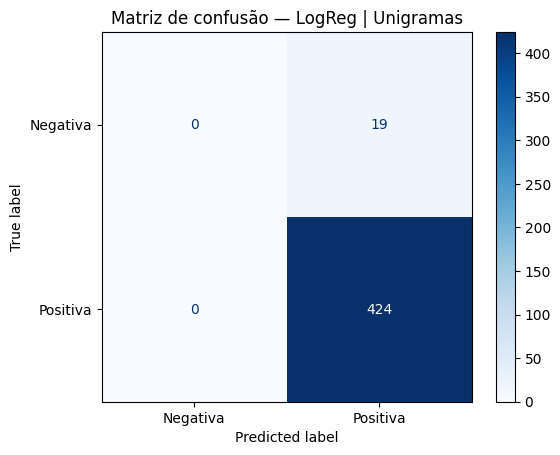

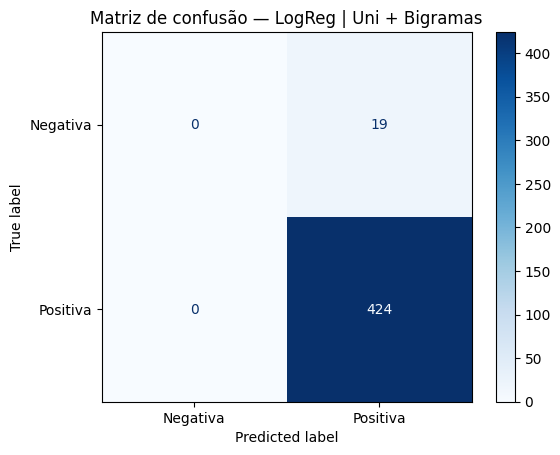

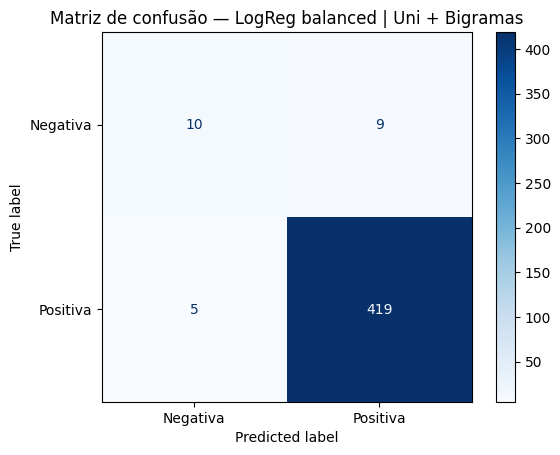

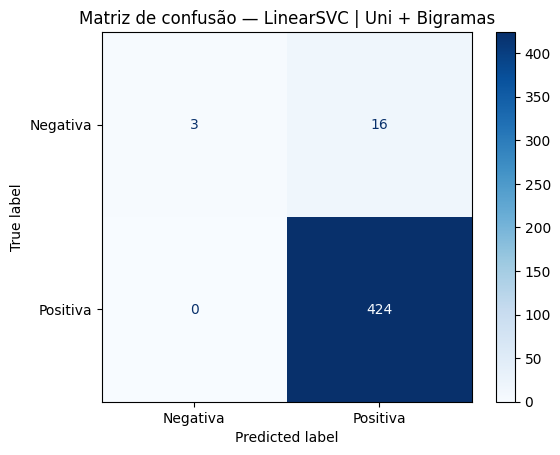

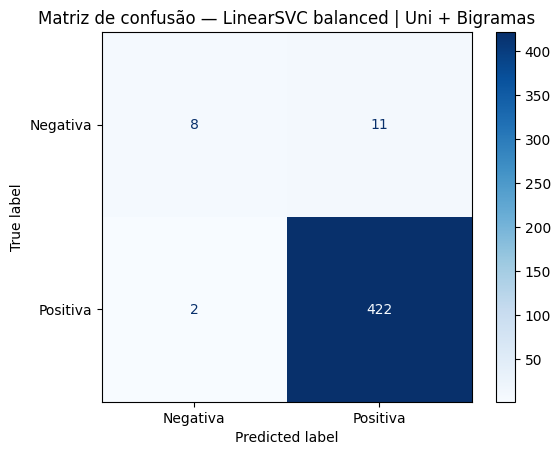

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

for name, result in fitted_models.items():
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=["Negativa", "Positiva"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusão — {name}")
    plt.show()